# Klasifikasi Bahasa Isyarat Indonesia (BISINDO)
## Studi Komparatif 6 Algoritma dengan Kondisi Kamera HP

- **Dataset**: 5.789 foto dari folder `images/train` (26 huruf A-Z, 127 fitur MediaPipe Hand Landmarks). Data dibuat oleh `ml/notebooks/01_preprocessing_dataset_foto.ipynb` di repo bisindo: duplikat dibuang, dan foto huruf B/P yang hanya terdeteksi satu tangan dibuang.
- **Algoritma**: KNN, Naive Bayes, SVM, Random Forest, MLP, dan 1D-CNN, masing-masing 3 varian (18 model). SVM RBF memakai pengaturan model server (C=30, gamma=0,004).

### Aturan uji (sama untuk semua model)
Tujuannya menjawab: *algoritma mana yang paling bagus mengenali tangan di kamera HP?*

1. **Pembagian per kelompok foto, 5 kali.** Foto yang nyaris kembar (jepretan beruntun, augmentasi gambar) selalu berada di sisi yang sama, latih atau uji. Hasil adalah rata-rata 5 pembagian, ditambah simpangan bakunya.
2. **Augmentasi yang sama.** Setiap data latih diperbanyak 3 kali dengan bentuk frame HP (potret 16:9), rotasi kecil, dan goyangan titik.
3. **Uji di frame HP.** Foto uji diregangkan ke bentuk frame HP 16:9, seperti koordinat yang dikirim aplikasi.
4. **Cara menebak seperti server.** Tiap sampel dicoba dalam bentuk asli, dicerminkan, dan dengan urutan tangan ditukar, lalu dipakai jawaban yang paling yakin.
5. **Uji tambahan tangan jauh.** Kondisi "jauh" ditiru dengan goyangan titik tambahan, karena titik MediaPipe kurang presisi saat tangan tampak kecil.

Hasil versi lama (pembagian acak satu kali, frame persegi) dibandingkan di bagian akhir.

In [1]:
import json
import os
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"

import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.naive_bayes import BernoulliNB, ComplementNB, GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import Binarizer, MinMaxScaler, StandardScaler
from sklearn.svm import SVC

# Fungsi augmentasi dan cara menebak diambil dari repo, supaya identik dengan model server.
REPO_ML_SRC = Path(r"C:\POLINEMA\SEMESTER 5\bisindo\ml\src")
sys.path.insert(0, str(REPO_ML_SRC))
from dataset.augment_landmarks import _join, _split, augment_dataset, stretch_aspect
from training.retrain_from_photos import PHONE_ASPECT, server_predict

BASE_DIR = Path(r"C:\POLINEMA\SEMESTER 5\ML\Klasifikasi_Bisindo_6_Algoritma")
NPZ_PATH = Path(r"C:\POLINEMA\SEMESTER 5\bisindo\ml\data\processed\dataset_bisindo_landmarks_foto.npz")
OUTPUT_DIR = BASE_DIR / "output_6_algorithms_frame_hp"
OLD_TABLE = Path(r"C:\POLINEMA\SEMESTER 5\CobaPBL\eksperimen_latih_ulang_bisindo\notebook_6_algoritma_split_acak\output_6_algorithms_split_acak\comparison_table_group_split.csv")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- Aturan uji ----------------
JUMLAH_LIPAT = 5
SALINAN_AUGMENTASI = 3
AUGMENTASI = dict(aspects=(PHONE_ASPECT,), aspect_jitter=0.12, include_original=False,
                  point_noise=(0.015, 0.035, 0.06))
GOYANGAN_JAUH = 0.05
SEED = 42

plt.rcParams["figure.dpi"] = 110
print(f"NumPy {np.__version__} | Pandas {pd.__version__} | TensorFlow {tf.__version__}")
print("NPZ:", NPZ_PATH, "| ada" if NPZ_PATH.exists() else "| TIDAK ADA, jalankan notebook 01 di repo")

NumPy 2.2.6 | Pandas 2.3.3 | TensorFlow 2.21.0
NPZ: C:\POLINEMA\SEMESTER 5\bisindo\ml\data\processed\dataset_bisindo_landmarks_foto.npz | ada


## 1. Data

Data          : 5789 foto x 127 fitur, 26 huruf
Kelompok foto : 2826


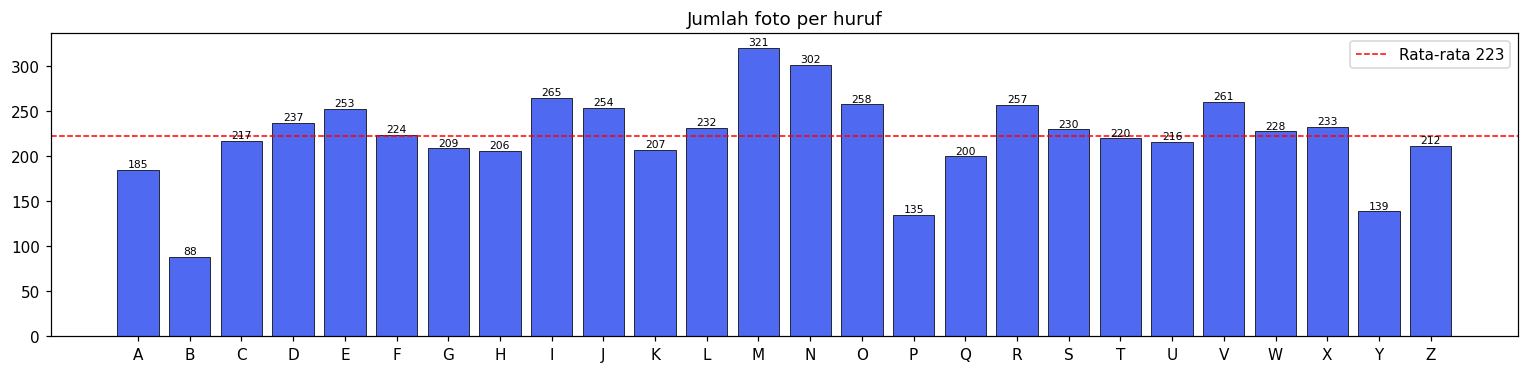

In [2]:
data = np.load(NPZ_PATH, allow_pickle=True)
X = data["X"].astype(np.float32)
labels = data["labels"].astype(str)
groups = data["groups"]
class_names = sorted(set(labels))
y = np.array([class_names.index(huruf) for huruf in labels])

print(f"Data          : {X.shape[0]} foto x {X.shape[1]} fitur, {len(class_names)} huruf")
print(f"Kelompok foto : {len(np.unique(groups))}")

jumlah = pd.Series(labels).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(14, 3.5))
ax.bar(jumlah.index, jumlah.values, color="#4F6AF0", edgecolor="black", lw=0.5)
ax.axhline(jumlah.mean(), color="red", ls="--", lw=1, label=f"Rata-rata {jumlah.mean():.0f}")
for x, v in zip(jumlah.index, jumlah.values):
    ax.text(x, v + 3, str(v), ha="center", fontsize=7)
ax.set_title("Jumlah foto per huruf"); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "00_distribusi_dataset.png"); plt.show()

## 2. Konfigurasi model
Pengaturan 18 model sama dengan notebook versi lama, kecuali **SVM RBF** yang memakai pengaturan hasil penyetelan yang dipakai server (C=30, gamma=0,004).

Semua model dibungkus `Pipeline` dengan penskalaan seperti versi lama. `MinMaxScaler` untuk Complement NB memakai `clip=True` karena Complement NB tidak menerima nilai negatif, sedangkan foto uji bisa sedikit di luar rentang data latih. SVM memakai `probability=True` agar keyakinannya bisa dibandingkan seperti di server. 1D-CNN diberi `predict_proba` dari keluaran softmax.

In [3]:
class CNN1DClassifier(BaseEstimator, ClassifierMixin):
    """1D-CNN TensorFlow/Keras sebagai estimator scikit-learn (arsitektur sama dengan versi lama)."""

    def __init__(self, variant="baseline", epochs=12, batch_size=64, lr=0.001, random_state=42):
        self.variant = variant
        self.epochs = epochs
        self.batch_size = batch_size
        self.lr = lr
        self.random_state = random_state

    def _build_model(self, input_dim, n_classes):
        tf.random.set_seed(self.random_state)
        np.random.seed(self.random_state)
        if self.variant == "baseline":
            m = models.Sequential([
                layers.Input(shape=(input_dim, 1)),
                layers.Conv1D(32, 3, activation="relu", padding="same"),
                layers.MaxPooling1D(2),
                layers.Conv1D(64, 3, activation="relu", padding="same"),
                layers.GlobalMaxPooling1D(),
                layers.Dense(128, activation="relu"),
                layers.Dense(n_classes, activation="softmax"),
            ])
        elif self.variant == "deep_bn":
            m = models.Sequential([
                layers.Input(shape=(input_dim, 1)),
                layers.Conv1D(32, 3, activation="relu", padding="same"),
                layers.BatchNormalization(),
                layers.MaxPooling1D(2),
                layers.Conv1D(64, 3, activation="relu", padding="same"),
                layers.BatchNormalization(),
                layers.MaxPooling1D(2),
                layers.Conv1D(128, 3, activation="relu", padding="same"),
                layers.BatchNormalization(),
                layers.GlobalAveragePooling1D(),
                layers.Dense(128, activation="relu"),
                layers.Dropout(0.3),
                layers.Dense(n_classes, activation="softmax"),
            ])
        else:  # wide
            m = models.Sequential([
                layers.Input(shape=(input_dim, 1)),
                layers.Conv1D(64, 5, activation="relu", padding="same"),
                layers.MaxPooling1D(2),
                layers.Conv1D(128, 5, activation="relu", padding="same"),
                layers.GlobalMaxPooling1D(),
                layers.Dense(128, activation="relu"),
                layers.Dropout(0.2),
                layers.Dense(n_classes, activation="softmax"),
            ])
        m.compile(optimizer=tf.keras.optimizers.Adam(self.lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
        return m

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.model_ = self._build_model(X.shape[1], len(self.classes_))
        self.model_.fit(np.expand_dims(X, -1), y, epochs=self.epochs, batch_size=self.batch_size, verbose=0)
        return self

    def predict_proba(self, X):
        return self.model_.predict(np.expand_dims(X, -1), verbose=0, batch_size=1024)

    def predict(self, X):
        return np.argmax(self.predict_proba(X), axis=1)


def std(model):
    return lambda: Pipeline([("sc", StandardScaler()), ("m", model())])


MODEL_CONFIGS = [
    ("KNN (k=3)", "KNN", std(lambda: KNeighborsClassifier(3, metric="euclidean", weights="distance", n_jobs=-1))),
    ("KNN (k=5)", "KNN", std(lambda: KNeighborsClassifier(5, metric="euclidean", weights="distance", n_jobs=-1))),
    ("KNN (k=7)", "KNN", std(lambda: KNeighborsClassifier(7, metric="euclidean", weights="distance", n_jobs=-1))),
    ("Naive Bayes Gaussian", "NaiveBayes", std(lambda: GaussianNB(var_smoothing=1e-9))),
    ("Naive Bayes Complement", "NaiveBayes",
     lambda: Pipeline([("mm", MinMaxScaler(clip=True)), ("m", ComplementNB(alpha=1.0))])),
    ("Naive Bayes Bernoulli", "NaiveBayes",
     lambda: Pipeline([("sc", StandardScaler()), ("bn", Binarizer(threshold=0.0)), ("m", BernoulliNB(alpha=1.0))])),
    ("SVM Linear", "SVM", std(lambda: SVC(kernel="linear", C=1.0, probability=True, random_state=SEED))),
    ("SVM RBF", "SVM", std(lambda: SVC(kernel="rbf", C=30.0, gamma=0.004, probability=True, random_state=SEED))),
    ("SVM Polynomial", "SVM", std(lambda: SVC(kernel="poly", C=1.0, degree=3, gamma="scale", probability=True, random_state=SEED))),
    ("Random Forest (100 Trees, Gini)", "RandomForest",
     std(lambda: RandomForestClassifier(100, criterion="gini", random_state=SEED, n_jobs=-1))),
    ("Random Forest (200 Trees, Entropy)", "RandomForest",
     std(lambda: RandomForestClassifier(200, criterion="entropy", random_state=SEED, n_jobs=-1))),
    ("Random Forest (100 Trees, Depth 15)", "RandomForest",
     std(lambda: RandomForestClassifier(100, max_depth=15, random_state=SEED, n_jobs=-1))),
    ("MLP (Hidden Layer: 128)", "MLP",
     std(lambda: MLPClassifier((128,), activation="relu", max_iter=300, random_state=SEED))),
    ("MLP (Hidden Layers: 128, 64)", "MLP",
     std(lambda: MLPClassifier((128, 64), activation="relu", max_iter=300, random_state=SEED))),
    ("MLP (Hidden Layers: 256, 128)", "MLP",
     std(lambda: MLPClassifier((256, 128), activation="relu", max_iter=300, random_state=SEED))),
    ("1D-CNN Baseline", "CNN", std(lambda: CNN1DClassifier("baseline"))),
    ("1D-CNN Deep + BatchNorm", "CNN", std(lambda: CNN1DClassifier("deep_bn"))),
    ("1D-CNN Wide (Kernel 5)", "CNN", std(lambda: CNN1DClassifier("wide"))),
]
print(f"{len(MODEL_CONFIGS)} model siap diuji")
for nama, algo, _ in MODEL_CONFIGS:
    print(f"  [{algo:<12}] {nama}")

18 model siap diuji
  [KNN         ] KNN (k=3)
  [KNN         ] KNN (k=5)
  [KNN         ] KNN (k=7)
  [NaiveBayes  ] Naive Bayes Gaussian
  [NaiveBayes  ] Naive Bayes Complement
  [NaiveBayes  ] Naive Bayes Bernoulli
  [SVM         ] SVM Linear
  [SVM         ] SVM RBF
  [SVM         ] SVM Polynomial
  [RandomForest] Random Forest (100 Trees, Gini)
  [RandomForest] Random Forest (200 Trees, Entropy)
  [RandomForest] Random Forest (100 Trees, Depth 15)
  [MLP         ] MLP (Hidden Layer: 128)
  [MLP         ] MLP (Hidden Layers: 128, 64)
  [MLP         ] MLP (Hidden Layers: 256, 128)
  [CNN         ] 1D-CNN Baseline
  [CNN         ] 1D-CNN Deep + BatchNorm
  [CNN         ] 1D-CNN Wide (Kernel 5)


## 3. Latih dan uji (5 pembagian per kelompok foto)
Bagian ini paling lama. Untuk setiap pembagian, data latih diaugmentasi sekali lalu dipakai bersama oleh semua model, sehingga semua model belajar dari data yang persis sama.

In [4]:
def goyang(matriks, besar, seed=7):
    titik, dua_tangan = _split(matriks)
    titik += np.random.default_rng(seed).normal(0.0, besar, titik.shape)
    return _join(titik, dua_tangan)


lipatan = list(StratifiedGroupKFold(JUMLAH_LIPAT, shuffle=True, random_state=SEED).split(X, y, groups))
hasil = {nama: [] for nama, _, _ in MODEL_CONFIGS}
tebakan = {nama: ([], []) for nama, _, _ in MODEL_CONFIGS}
mulai_semua = time.time()

for nomor, (latih, uji) in enumerate(lipatan, start=1):
    x_aug, y_aug = augment_dataset(X[latih], y[latih], SALINAN_AUGMENTASI, seed=SEED, **AUGMENTASI)
    uji_dekat = stretch_aspect(X[uji], PHONE_ASPECT)
    uji_jauh = stretch_aspect(goyang(X[uji], GOYANGAN_JAUH), PHONE_ASPECT)
    latih_hp = stretch_aspect(X[latih], PHONE_ASPECT)
    print(f"\n=== Pembagian {nomor}/{JUMLAH_LIPAT}: latih {len(latih)} foto (+augmentasi {len(x_aug)} baris), uji {len(uji)} foto ===")

    for nama, algo, buat in MODEL_CONFIGS:
        model = buat()
        t0 = time.time(); model.fit(x_aug, y_aug); waktu_latih = time.time() - t0

        pred_dekat = server_predict(model, uji_dekat)
        pred_jauh = server_predict(model, uji_jauh)
        pred_latih = server_predict(model, latih_hp)
        t0 = time.time(); model.predict_proba(uji_dekat[:200]); ms = (time.time() - t0) / 200 * 1000

        y_uji = y[uji]
        hasil[nama].append({
            "accuracy": accuracy_score(y_uji, pred_dekat),
            "precision": precision_score(y_uji, pred_dekat, average="weighted", zero_division=0),
            "recall": recall_score(y_uji, pred_dekat, average="weighted", zero_division=0),
            "f1": f1_score(y_uji, pred_dekat, average="weighted", zero_division=0),
            "f1_macro": f1_score(y_uji, pred_dekat, average="macro", zero_division=0),
            "accuracy_jauh": accuracy_score(y_uji, pred_jauh),
            "f1_jauh": f1_score(y_uji, pred_jauh, average="weighted", zero_division=0),
            "accuracy_latih": accuracy_score(y[latih], pred_latih),
            "train_time": waktu_latih,
            "ms_per_tebakan": ms,
        })
        tebakan[nama][0].extend(y_uji); tebakan[nama][1].extend(pred_dekat)
        print(f"  {nama:<45} akurasi {hasil[nama][-1]['accuracy']:.4f} | F1 {hasil[nama][-1]['f1']:.4f} "
              f"| latih {waktu_latih:6.1f} s | total {time.time() - mulai_semua:6.0f} s")

print(f"\nSelesai dalam {(time.time() - mulai_semua) / 60:.1f} menit")


=== Pembagian 1/5: latih 4410 foto (+augmentasi 13230 baris), uji 1379 foto ===


  KNN (k=3)                                     akurasi 0.7433 | F1 0.7617 | latih    0.0 s | total      2 s


  KNN (k=5)                                     akurasi 0.7404 | F1 0.7533 | latih    0.0 s | total      3 s


  KNN (k=7)                                     akurasi 0.7172 | F1 0.7207 | latih    0.0 s | total      5 s


  Naive Bayes Gaussian                          akurasi 0.3669 | F1 0.3240 | latih    0.1 s | total      6 s
  Naive Bayes Complement                        akurasi 0.1124 | F1 0.0521 | latih    0.1 s | total      6 s


  Naive Bayes Bernoulli                         akurasi 0.2690 | F1 0.2647 | latih    0.1 s | total      6 s


... (76 outputs left out)

  MLP (Hidden Layers: 256, 128)                 akurasi 0.9225 | F1 0.9221 | latih   31.3 s | total   1456 s


  1D-CNN Baseline                               akurasi 0.6661 | F1 0.6502 | latih   19.7 s | total   1478 s


  1D-CNN Deep + BatchNorm                       akurasi 0.7894 | F1 0.7765 | latih   41.5 s | total   1522 s


  1D-CNN Wide (Kernel 5)                        akurasi 0.7251 | F1 0.7212 | latih   27.9 s | total   1554 s

Selesai dalam 25.9 menit


## 4. Tabel perbandingan
Semua angka adalah rata-rata 5 pembagian pada foto uji di frame HP.

- **Accuracy, Precision, Recall, F1-Score**: precision, recall, dan F1 ditimbang jumlah foto tiap huruf. Karena dihitung dari 5 pembagian, F1-Score di sini setara dengan *CV F1 Mean* pada notebook versi lama.
- **± F1**: simpangan baku F1 antar pembagian. Makin kecil makin stabil.
- **Waktu latih**: detik per pembagian.

Tabel 2 memuat uji tambahan: F1 saat tangan jauh dari kamera, selisih akurasi latih dan uji (overfitting), dan waktu menebak.

In [5]:
baris = []
for nama, algo, _ in MODEL_CONFIGS:
    df = pd.DataFrame(hasil[nama])
    baris.append({
        "Model": nama, "Algoritma": algo,
        "Accuracy": df["accuracy"].mean(), "Precision": df["precision"].mean(),
        "Recall": df["recall"].mean(), "F1": df["f1"].mean(), "± F1": df["f1"].std(ddof=0),
        "F1 macro": df["f1_macro"].mean(), "F1 (jauh)": df["f1_jauh"].mean(),
        "Accuracy latih": df["accuracy_latih"].mean(),
        "Selisih latih-uji": df["accuracy_latih"].mean() - df["accuracy"].mean(),
        "Waktu latih (s)": df["train_time"].mean(), "ms per tebakan": df["ms_per_tebakan"].mean(),
    })
tabel = pd.DataFrame(baris).sort_values("F1", ascending=False).reset_index(drop=True)
tabel.index = tabel.index + 1
tabel["Penurunan tangan jauh"] = tabel["F1"] - tabel["F1 (jauh)"]
tabel.to_csv(OUTPUT_DIR / "comparison_table.csv")

utama = tabel[["Model", "Accuracy", "Precision", "Recall", "F1", "± F1", "Waktu latih (s)"]].rename(columns={"F1": "F1-Score"})
display(utama.style
        .format({c: "{:.4f}" for c in utama.columns if c not in ("Model", "Waktu latih (s)")} | {"Waktu latih (s)": "{:.1f}"})
        .highlight_max(subset=["Accuracy", "F1-Score"], color="#e2f0d9")
        .highlight_min(subset=["± F1"], color="#e2f0d9")
        .set_caption("Tabel 1: Perbandingan 18 model di kondisi kamera HP (rata-rata 5 pembagian per kelompok foto)"))

tambahan = tabel[["Model", "F1", "F1 (jauh)", "Penurunan tangan jauh", "Selisih latih-uji", "ms per tebakan"]].rename(
    columns={"F1": "F1 tangan dekat", "F1 (jauh)": "F1 tangan jauh"})
display(tambahan.style
        .format({c: "{:.4f}" for c in tambahan.columns if c not in ("Model", "ms per tebakan")} | {"ms per tebakan": "{:.3f}"})
        .highlight_max(subset=["F1 tangan jauh"], color="#e2f0d9")
        .highlight_min(subset=["Penurunan tangan jauh", "Selisih latih-uji"], color="#e2f0d9")
        .set_caption("Tabel 2: Uji tambahan: tangan jauh, overfitting, dan kecepatan menebak"))


,Model,Accuracy,Precision,Recall,F1-Score,± F1,Waktu latih (s)
1,SVM RBF,0.8656,0.9354,0.8656,0.8656,0.0635,16.9
2,"Random Forest (100 Trees, Gini)",0.8561,0.9134,0.8561,0.8561,0.0697,2.4
3,"Random Forest (200 Trees, Entropy)",0.8474,0.9145,0.8474,0.8490,0.0652,11.5
4,MLP (Hidden Layer: 128),0.8429,0.8982,0.8429,0.8460,0.0634,29.3
5,"MLP (Hidden Layers: 256, 128)",0.8487,0.9165,0.8487,0.8456,0.0714,31.5
6,"Random Forest (100 Trees, Depth 15)",0.8345,0.9056,0.8345,0.8380,0.0676,2.1
7,"MLP (Hidden Layers: 128, 64)",0.8002,0.9037,0.8002,0.8061,0.0883,21.6
8,SVM Linear,0.7984,0.8836,0.7984,0.7964,0.0486,16.6
9,KNN (k=3),0.7787,0.8540,0.7787,0.7867,0.0392,0.0
10,KNN (k=5),0.7785,0.8599,0.7785,0.7817,0.0439,0.0


,Model,F1 tangan dekat,F1 tangan jauh,Penurunan tangan jauh,Selisih latih-uji,ms per tebakan
1,SVM RBF,0.8656,0.8563,0.0093,0.1183,0.973
2,"Random Forest (100 Trees, Gini)",0.8561,0.8362,0.0199,0.1191,0.268
3,"Random Forest (200 Trees, Entropy)",0.8490,0.8269,0.0221,0.1295,0.430
4,MLP (Hidden Layer: 128),0.8460,0.8208,0.0252,0.1158,0.007
5,"MLP (Hidden Layers: 256, 128)",0.8456,0.8301,0.0155,0.1136,0.010
6,"Random Forest (100 Trees, Depth 15)",0.8380,0.8194,0.0186,0.1259,0.287
7,"MLP (Hidden Layers: 128, 64)",0.8061,0.7861,0.0200,0.1458,0.012
8,SVM Linear,0.7964,0.7713,0.0251,0.1449,0.389
9,KNN (k=3),0.7867,0.7557,0.0310,0.1889,0.066
10,KNN (k=5),0.7817,0.7580,0.0237,0.1767,0.067


### Analisis tabel

- **SVM RBF berada di peringkat pertama** (F1 0,866), diikuti Random Forest (0,856) dan MLP (0,846). Selisih peringkat 1 sampai 6 hanya sekitar 3 poin, lebih kecil daripada naik-turun antar pembagian (±6-7 poin), jadi keunggulan SVM RBF dalam akurasi tipis. Alasan memilihnya juga bertumpu pada ketahanan saat tangan jauh (Tabel 2).
- **F1 macro SVM RBF (0,884) lebih tinggi daripada F1 weighted (0,866).** Kesalahan menumpuk di huruf yang fotonya banyak (M dan N, masing-masing lebih dari 300 foto), sehingga rata-rata yang ditimbang jumlah foto ikut turun. Rata-rata per huruf justru lebih baik.
- **Selisih latih-uji (overfitting).** Model-model terbaik punya selisih sekitar 0,11-0,13. Selisih ini terutama berasal dari huruf yang kelompok fotonya besar (N, M, V): saat kelompok itu menjadi data uji, model kekurangan contoh variasinya. **KNN** punya selisih terbesar di antara model dengan F1 di atas 0,75 (0,18-0,19) karena menghafal foto latih. **Naive Bayes** punya selisih kecil tetapi akurasi latihnya juga rendah: bukan overfitting, melainkan model yang terlalu sederhana (underfitting).

## 5. Visualisasi

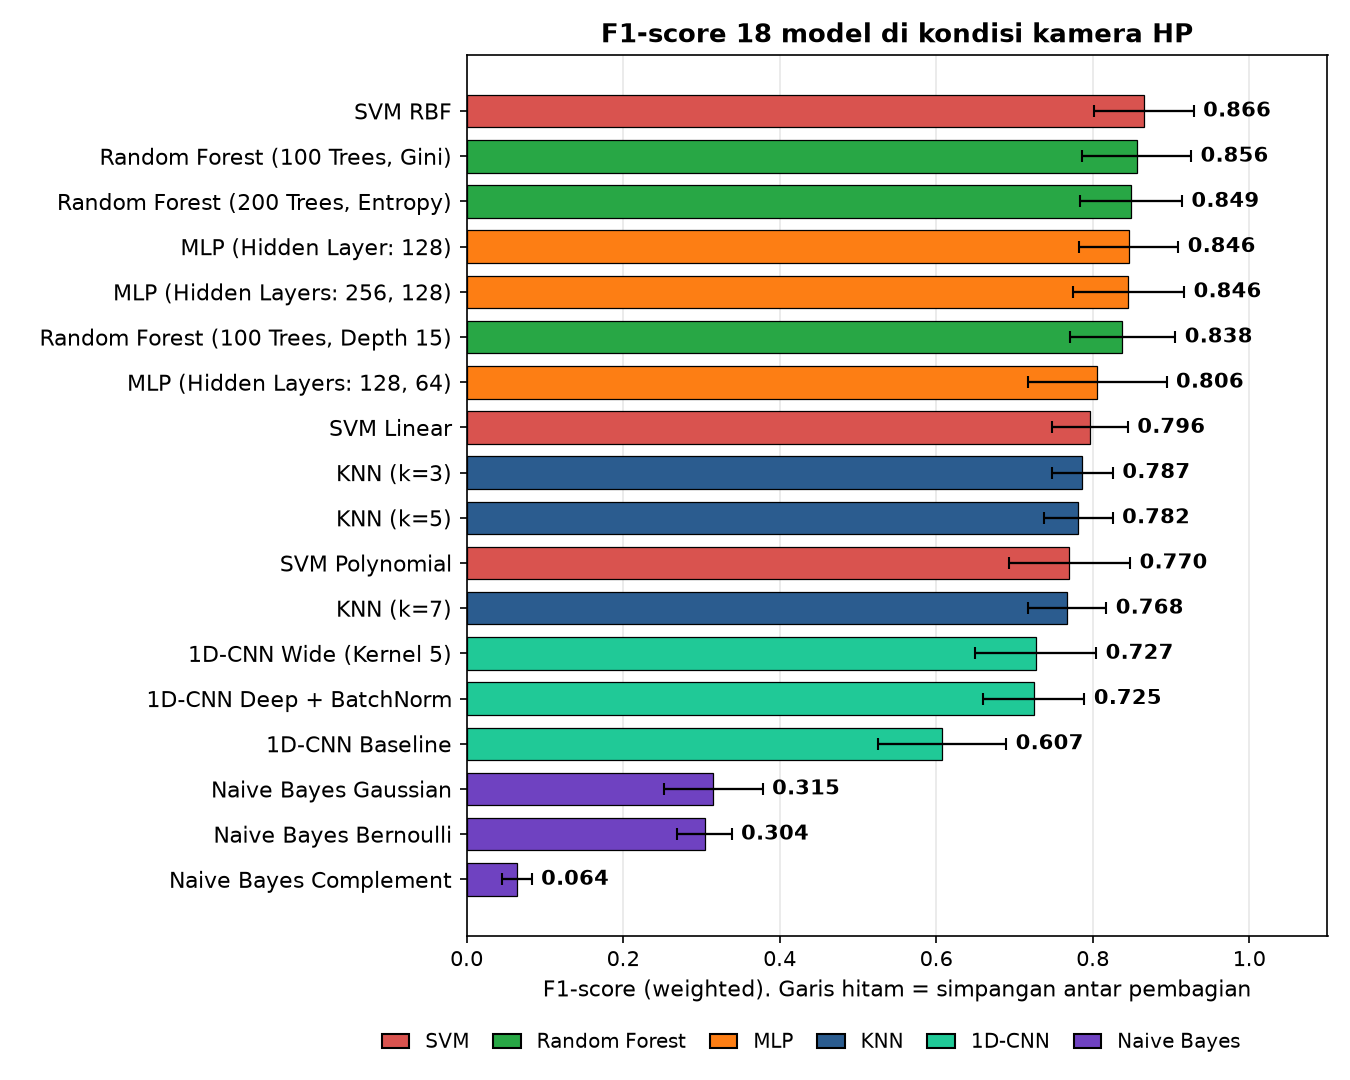

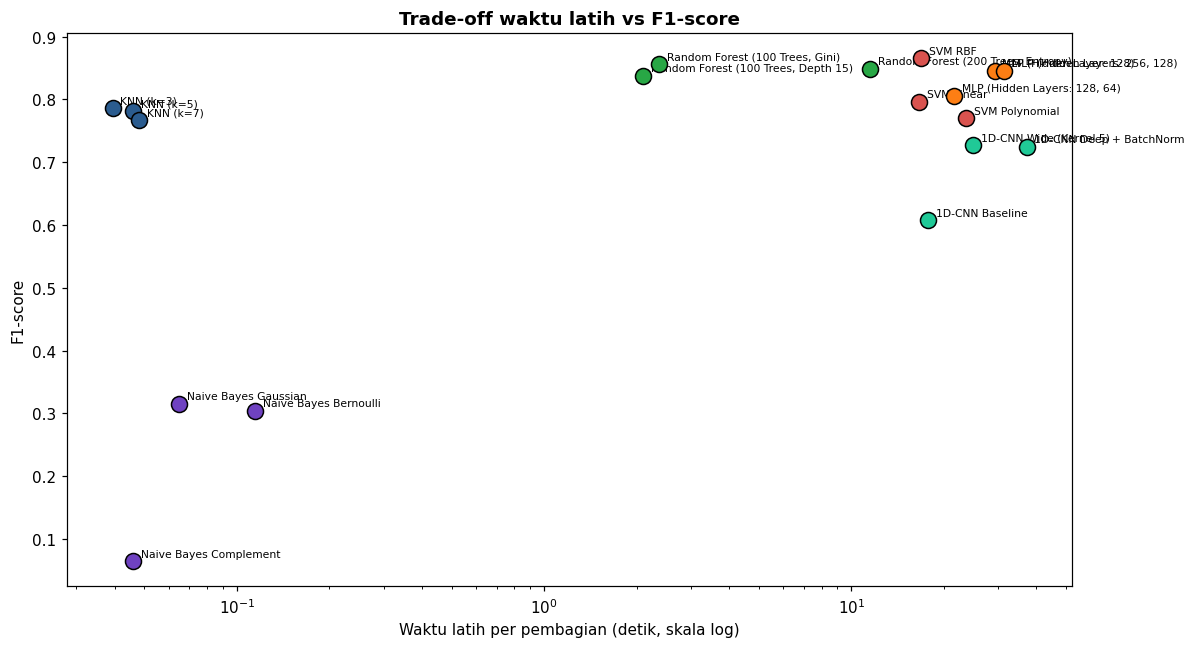

In [6]:
from matplotlib.patches import Patch

WARNA = {"KNN": "#2b5c8f", "NaiveBayes": "#6f42c1", "SVM": "#d9534f",
         "RandomForest": "#28a745", "MLP": "#fd7e14", "CNN": "#20c997"}

urut = tabel.sort_values("F1")
nama_algo = {"SVM": "SVM", "RandomForest": "Random Forest", "MLP": "MLP", "KNN": "KNN", "CNN": "1D-CNN", "NaiveBayes": "Naive Bayes"}
fig, ax = plt.subplots(figsize=(9, 7.2))
ax.barh(urut["Model"], urut["F1"], color=[WARNA[a] for a in urut["Algoritma"]], edgecolor="black", lw=0.6, height=0.72)
ax.errorbar(urut["F1"], range(len(urut)), xerr=urut["± F1"], fmt="none", ecolor="black", elinewidth=1.1, capsize=3, zorder=4)
for posisi, (nilai, galat) in enumerate(zip(urut["F1"], urut["± F1"])):
    ax.text(nilai + galat + 0.012, posisi, f"{nilai:.3f}", va="center", fontsize=10, fontweight="bold")
ax.set_xlim(0, 1.1); ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax.tick_params(axis="y", labelsize=10.5); ax.tick_params(axis="x", labelsize=10)
ax.set_xlabel("F1-score (weighted). Garis hitam = simpangan antar pembagian", fontsize=10.5)
ax.grid(axis="x", alpha=0.3); ax.set_axisbelow(True)
ax.set_title("F1-score 18 model di kondisi kamera HP", fontsize=12.5, fontweight="bold")
ax.legend(handles=[Patch(facecolor=WARNA[k], edgecolor="black", label=v) for k, v in nama_algo.items()],
          loc="upper center", bbox_to_anchor=(0.4, -0.09), ncol=6, fontsize=9.5, frameon=False, columnspacing=1.2, handlelength=1.4)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "01_f1_frame_hp.png", dpi=150); plt.show()

fig, ax = plt.subplots(figsize=(11, 6))
for _, r in tabel.iterrows():
    ax.scatter(r["Waktu latih (s)"], r["F1"], s=110, color=WARNA[r["Algoritma"]], edgecolors="black", zorder=5)
    ax.annotate(r["Model"], (r["Waktu latih (s)"], r["F1"]), xytext=(5, 3), textcoords="offset points", fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("Waktu latih per pembagian (detik, skala log)"); ax.set_ylabel("F1-score")
ax.set_title("Trade-off waktu latih vs F1-score", fontweight="bold")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "02_tradeoff_waktu_f1.png"); plt.show()

### Analisis grafik

- **Kestabilan.** Garis kesalahan (±) pada model-model terbaik sekitar 6-7 poin. Pembagian ke-4 paling sulit untuk 15 dari 18 model, termasuk model-model terbaik (F1 pada pembagian itu: SVM RBF 0,754, Random Forest (100 Trees, Gini) 0,732, MLP (Hidden Layer: 128) 0,736). Pada pembagian itu, kelompok 191 foto N yang nyaris kembar jatuh ke data uji, sehingga ada 210 foto N di data uji (pembagian lain hanya 20-25) dan model hanya belajar dari sedikit variasi N. Jadi naik-turun ini berasal dari data, bukan dari algoritma tertentu.
- **Tangan jauh.** Semua model turun saat titik tangan lebih goyang, tetapi besarnya berbeda: SVM RBF hanya 0,9 poin, Random Forest (100 Trees, Gini) 2,0 poin, MLP (Hidden Layer: 128) 2,5 poin, KNN (k=3) 3,1 poin, dan 1D-CNN Wide (Kernel 5) 4,8 poin. Di antara model dengan F1 di atas 0,7, penurunan SVM RBF paling kecil.
- **Waktu latih vs F1.** Random Forest (sekitar 2 detik) dan KNN (kurang dari 0,1 detik) paling cepat dilatih tetapi F1-nya lebih rendah. SVM RBF butuh sekitar 17 detik per pembagian, masih sangat wajar untuk dilatih ulang kapan saja. Untuk waktu menebak, semua model sekitar 1 ms atau kurang (SVM RBF 0,97 ms), jauh lebih kecil daripada waktu kirim data dari HP ke server.

## 6. Model terbaik per algoritma

,Algoritma,Model,Accuracy,Precision,Recall,F1-Score,± F1
1,SVM,SVM RBF,0.8656,0.9354,0.8656,0.8656,0.0635
2,RandomForest,"Random Forest (100 Trees, Gini)",0.8561,0.9134,0.8561,0.8561,0.0697
4,MLP,MLP (Hidden Layer: 128),0.8429,0.8982,0.8429,0.8460,0.0634
9,KNN,KNN (k=3),0.7787,0.8540,0.7787,0.7867,0.0392
13,CNN,1D-CNN Wide (Kernel 5),0.7241,0.8334,0.7241,0.7273,0.0772
16,NaiveBayes,Naive Bayes Gaussian,0.3738,0.4312,0.3738,0.3153,0.0631


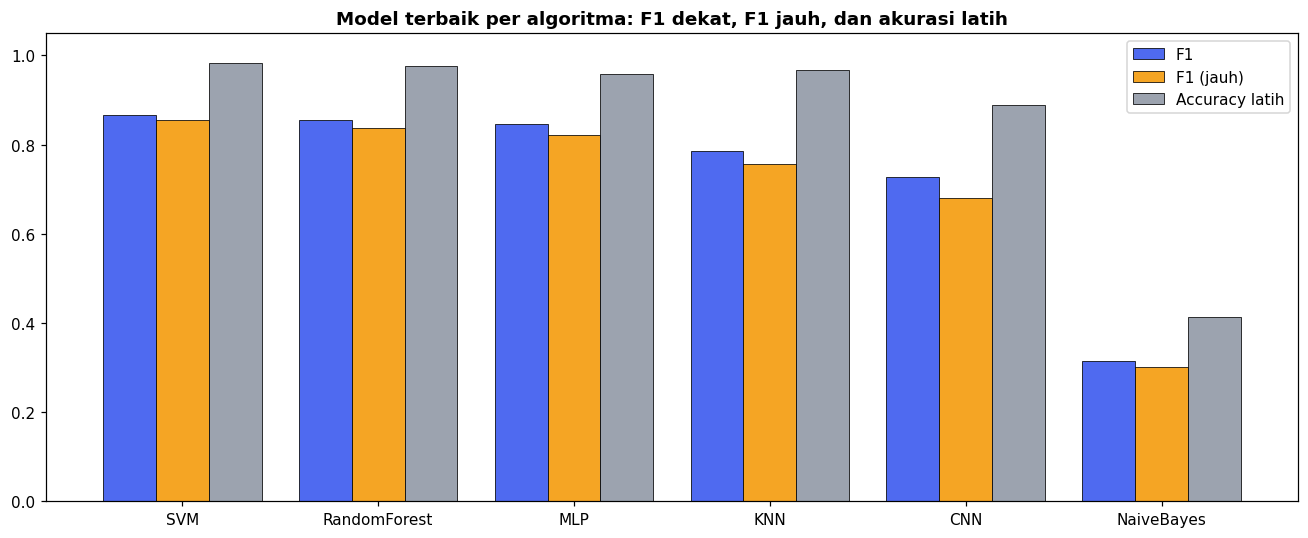

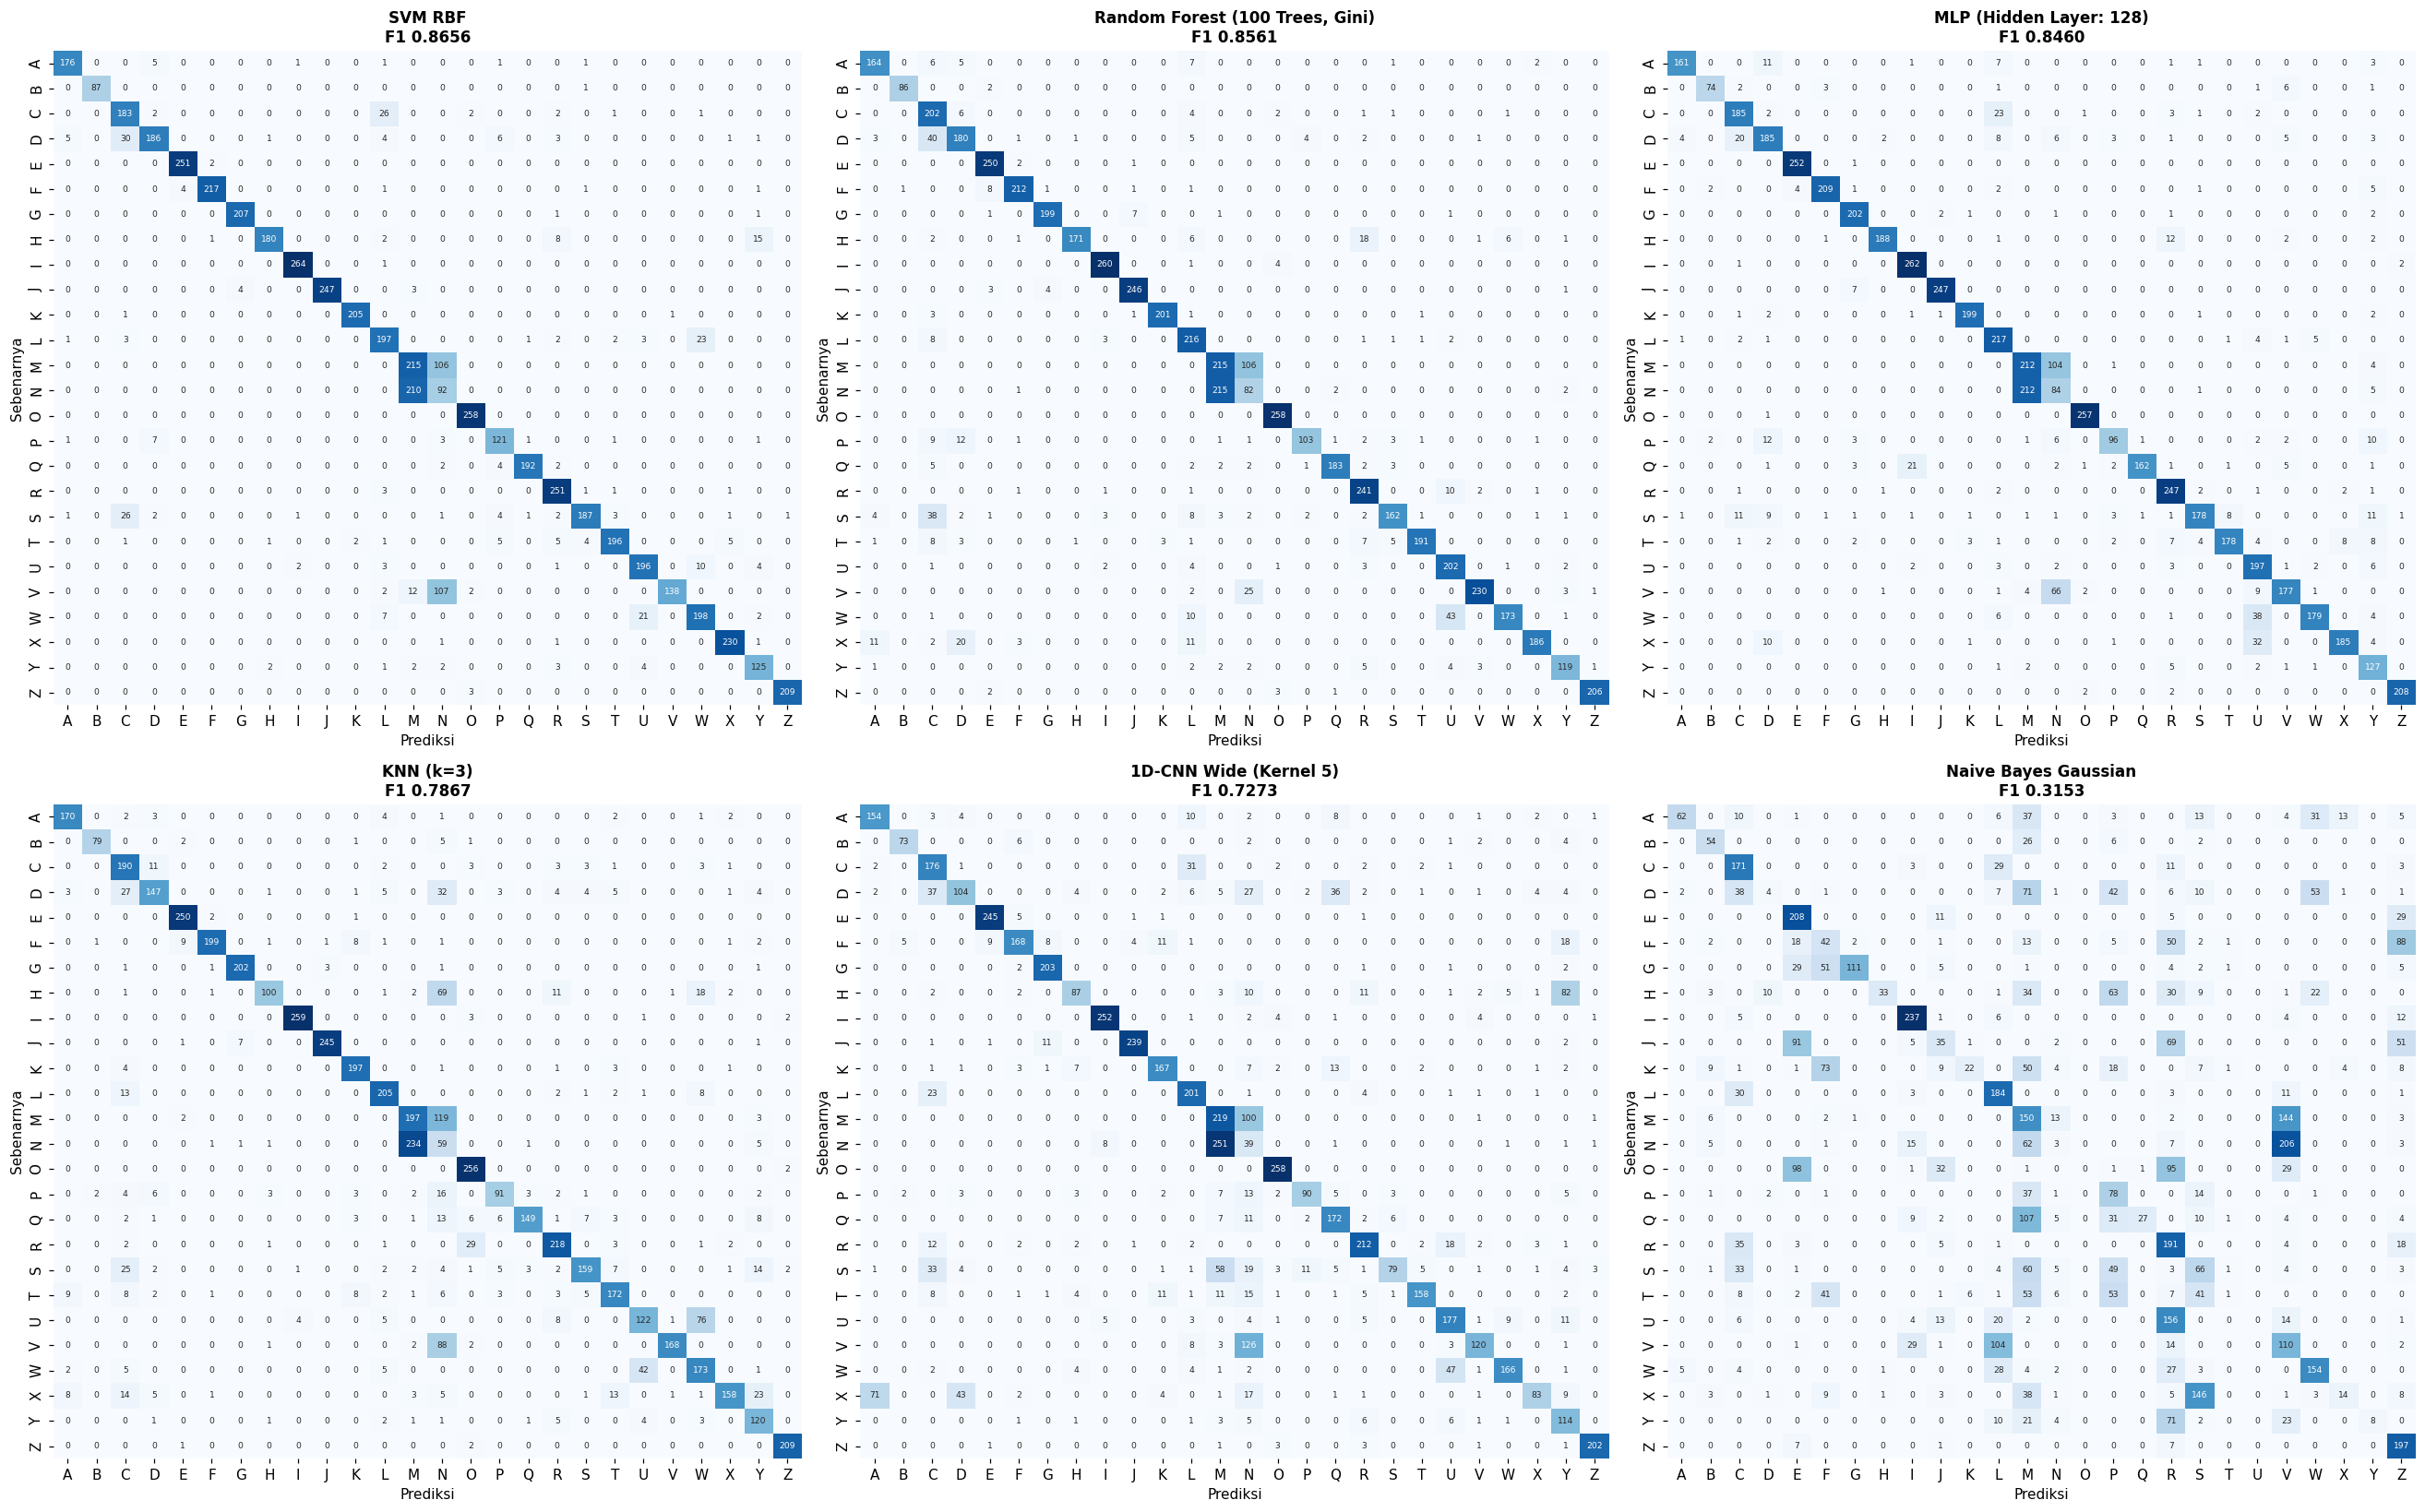

In [7]:
terbaik = tabel.loc[tabel.groupby("Algoritma")["F1"].idxmax()].sort_values("F1", ascending=False)
terbaik_tampil = terbaik[["Algoritma", "Model", "Accuracy", "Precision", "Recall", "F1", "± F1"]].rename(columns={"F1": "F1-Score"})
display(terbaik_tampil.style.format({c: "{:.4f}" for c in terbaik_tampil.columns if c not in ("Algoritma", "Model")})
        .set_caption("Tabel 3: Model terbaik setiap algoritma"))

fig, ax = plt.subplots(figsize=(12, 5))
lebar = 0.27
x = np.arange(len(terbaik))
for geser, kolom, warna in ((-lebar, "F1", "#4F6AF0"), (0, "F1 (jauh)", "#F5A524"), (lebar, "Accuracy latih", "#9CA3AF")):
    ax.bar(x + geser, terbaik[kolom], lebar, label=kolom, color=warna, edgecolor="black", lw=0.5)
ax.set_xticks(x); ax.set_xticklabels(terbaik["Algoritma"]); ax.set_ylim(0, 1.05)
ax.set_title("Model terbaik per algoritma: F1 dekat, F1 jauh, dan akurasi latih", fontweight="bold"); ax.legend()
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "03_terbaik_per_algoritma.png"); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(24, 15))
for ax, (_, r) in zip(axes.ravel(), terbaik.iterrows()):
    benar, tebak = tebakan[r["Model"]]
    sns.heatmap(confusion_matrix(benar, tebak), cmap="Blues", cbar=False, ax=ax, annot=True, fmt="d",
                annot_kws={"size": 6}, xticklabels=class_names, yticklabels=class_names)
    ax.set_title(f"{r['Model']}\nF1 {r['F1']:.4f}", fontsize=11, fontweight="bold")
    ax.set_xlabel("Prediksi"); ax.set_ylabel("Sebenarnya")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "04_cm_terbaik_per_algoritma.png"); plt.show()

### Analisis per algoritma

| Algoritma | F1 dekat | Kenapa hasilnya begitu |
| :--- | ---: | :--- |
| **SVM RBF** | 0,866 | Fitur berupa 127 angka kontinu yang sudah dinormalkan. Kernel RBF membentuk batas melengkung yang halus antar huruf, cocok untuk data seperti ini, dan margin yang lebar membuatnya tahan terhadap goyangan titik (penurunan saat tangan jauh hanya 0,9 poin). |
| **Random Forest** | 0,856 | Kuat menangkap kombinasi fitur, tetapi setiap pohon memotong ruang fitur dengan garis tegak lurus sumbu. Pola tangan yang sedikit berputar atau teregang membutuhkan banyak potongan, sehingga lebih turun saat tangan jauh (2,0 poin). Kelebihannya: latih sangat cepat (sekitar 2 detik). |
| **MLP** | 0,846 | Mampu memodelkan pola kompleks, tetapi dengan pengaturan bawaan (300 iterasi, tanpa penyetelan regularisasi) hasilnya kurang stabil antar varian: (128) 0,846, (256, 128) 0,846, (128, 64) 0,806. Tebakannya paling cepat (sekitar 0,007 ms). |
| **KNN** | 0,787 | Menebak dari foto latih terdekat. Selisih latih-uji paling besar di antara model dengan F1 di atas 0,75 (0,18-0,19) karena pada dasarnya menghafal foto latih. Di ruang 127 dimensi, jarak antar titik mudah terganggu goyangan, sehingga turun 3,1 poin saat tangan jauh. |
| **1D-CNN** | 0,727 | Konvolusi 1D cocok untuk sinyal berurutan seperti suara. Urutan 127 fitur di sini bukan sinyal: angka yang bersebelahan adalah x, y, z dari titik yang sama atau titik yang berbeda, bukan nilai yang bergeser dalam waktu. Data latih (sekitar 14 ribu baris setelah augmentasi) juga kecil untuk jaringan saraf. Hasilnya turun 4,8 poin saat tangan jauh, dan **berubah-ubah setiap notebook dijalankan** karena pelatihan TensorFlow di CPU tidak persis sama: pada run sebelumnya Deep + BatchNorm mendapat F1 0,785, pada run ini 0,725. |
| **Naive Bayes** | 0,315 | Mengasumsikan setiap fitur saling bebas, padahal koordinat titik-titik jari sangat saling bergantung (titik ujung jari selalu mengikuti pangkalnya). Selisih latih-uji kecil, tetapi akurasi latihnya pun rendah (di bawah 0,42): ini **underfitting**, model terlalu sederhana. Complement dan Bernoulli NB dirancang untuk data hitungan atau biner (misalnya kata dalam teks), sehingga paling buruk. |

In [8]:
tertukar_rows = []
for _, r in terbaik.iterrows():
    benar, tebak = tebakan[r["Model"]]
    cm = confusion_matrix(benar, tebak)
    total_huruf = cm.sum(axis=1)
    pasangan = sorted(((int(cm[a, b]), class_names[a], class_names[b])
                       for a in range(len(class_names)) for b in range(len(class_names)) if a != b), reverse=True)[:5]
    recall = {class_names[i]: cm[i, i] / total_huruf[i] for i in range(len(class_names))}
    lemah = sorted(recall.items(), key=lambda kv: kv[1])[:4]
    tertukar_rows.append({
        "Algoritma": r["Algoritma"],
        "Model": r["Model"],
        "5 pasangan paling sering tertukar": ", ".join(f"{a}->{b} ({n})" for n, a, b in pasangan),
        "4 huruf terlemah (recall)": ", ".join(f"{h} {v:.2f}" for h, v in lemah),
    })
tertukar = pd.DataFrame(tertukar_rows)
pd.set_option("display.max_colwidth", 200)
display(tertukar.style.set_caption("Tabel 4: Huruf yang paling sering tertukar (total 5 pembagian, foto uji frame HP)"))

,Algoritma,Model,5 pasangan paling sering tertukar,4 huruf terlemah (recall)
0,SVM,SVM RBF,"N->M (210), V->N (107), M->N (106), D->C (30), S->C (26)","N 0.30, V 0.53, M 0.67, D 0.78"
1,RandomForest,"Random Forest (100 Trees, Gini)","N->M (215), M->N (106), W->U (43), D->C (40), S->C (38)","N 0.27, M 0.67, S 0.70, W 0.76"
2,MLP,MLP (Hidden Layer: 128),"N->M (212), M->N (104), V->N (66), W->U (38), X->U (32)","N 0.28, M 0.66, V 0.68, P 0.71"
3,KNN,KNN (k=3),"N->M (234), M->N (119), V->N (88), U->W (76), H->N (69)","N 0.20, H 0.49, U 0.56, M 0.61"
4,CNN,1D-CNN Wide (Kernel 5),"N->M (251), V->N (126), M->N (100), H->Y (82), X->A (71)","N 0.13, S 0.34, X 0.36, H 0.42"
5,NaiveBayes,Naive Bayes Gaussian,"N->V (206), U->R (156), X->S (146), M->V (144), Q->M (107)","O 0.00, U 0.00, T 0.00, N 0.01"


### Analisis huruf yang tertukar

- **N dan M tertukar di hampir semua algoritma**: N terbaca M 210-251 kali dan M terbaca N 100-119 kali pada SVM, Random Forest, MLP, KNN, dan CNN. Karena polanya sama di lima algoritma yang sangat berbeda cara kerjanya, penyebabnya ada di **data**, bukan algoritma. Pada kebanyakan foto N (76%) dan M (46%), MediaPipe hanya menangkap telapak terbuka, sementara jari tangan kedua yang membedakan M (tiga jari) dan N (dua jari) tertutup. Selain itu, 191 dari 302 foto N nyaris kembar, sehingga saat kelompok itu menjadi data uji, model hanya belajar dari sedikit variasi N.
- **V terbaca N** (66-126 kali pada SVM, MLP, KNN, dan CNN). Bila tangan kedua N/M tidak tertangkap, sisanya berupa tangan dengan jari terbuka yang mirip V.
- **W dan U** saling tertukar pada Random Forest (W terbaca U 43 kali), MLP (38 kali), dan KNN (U terbaca W 76 kali). Keduanya memakai telunjuk dan jari tengah yang terangkat. Bedanya W dibentuk dua tangan, dan bila satu tangan tidak terdeteksi, W tampak seperti U.
- **D terbaca C** (30-40 kali pada SVM dan Random Forest). Separuh huruf D (satu tangan dengan telunjuk dan jempol melengkung) mirip C bila tangan kedua tidak tertangkap.
- **1D-CNN punya kesalahan khas**: H terbaca Y (82 kali) dan X terbaca A (71 kali), yang tidak termasuk lima kesalahan teratas pada algoritma lain.
- **Naive Bayes** gagal total di beberapa huruf (recall O, U, dan T bernilai 0), sehingga pasangan tertukarnya tidak bermakna.

Kesimpulannya, kesalahan terbesar berasal dari foto huruf dua tangan yang hanya terdeteksi satu tangannya. Mengganti algoritma tidak akan banyak membantu; yang membantu adalah menambah foto M, N, V, dan W dengan kedua tangan terlihat jelas.

## 7. Dibandingkan dengan versi lama
Versi lama memakai data 6.108 foto (tanpa membuang foto B/P satu tangan), tanpa augmentasi, uji di frame persegi seperti foto dataset, dan satu kali pembagian. SVM RBF lama memakai C=10 dan gamma bawaan, SVM RBF baru memakai C=30 dan gamma=0,004. Kolom **Peringkat lama** dan **Peringkat baru** menunjukkan bagaimana urutan berubah setelah aturan uji disamakan dengan kondisi kamera HP.

In [9]:
if OLD_TABLE.exists():
    lama = pd.read_csv(OLD_TABLE, index_col=0)[["Model", "F1 (Split Acak)", "F1 (Per Foto)"]]
    lama = lama.rename(columns={"F1 (Split Acak)": "F1 lama (acak, persegi)", "F1 (Per Foto)": "F1 lama (per foto, persegi)"})
    lama["Peringkat lama"] = lama["F1 lama (per foto, persegi)"].rank(ascending=False).astype(int)
    banding = tabel[["Model", "F1"]].rename(columns={"F1": "F1 baru (frame HP, 5x)"})
    banding["Peringkat baru"] = banding["F1 baru (frame HP, 5x)"].rank(ascending=False).astype(int)
    banding = banding.merge(lama, on="Model", how="left").sort_values("Peringkat baru")
    print("Catatan: SVM RBF lama memakai C=10 dan gamma bawaan; SVM RBF baru memakai C=30 dan gamma=0,004.")
    banding["Peringkat lama"] = banding["Peringkat lama"].astype("Int64")
    display(banding.style.format({c: "{:.4f}" for c in banding.columns if c.startswith("F1")}, na_rep="-")
            .set_caption("Tabel 5: Versi lama vs aturan uji kamera HP"))
else:
    print("Tabel versi lama tidak ditemukan:", OLD_TABLE)

Catatan: SVM RBF lama memakai C=10 dan gamma bawaan; SVM RBF baru memakai C=30 dan gamma=0,004.


,Model,"F1 baru (frame HP, 5x)",Peringkat baru,"F1 lama (acak, persegi)","F1 lama (per foto, persegi)",Peringkat lama
0,SVM RBF,0.8656,1,0.9337,0.8877,5
1,"Random Forest (100 Trees, Gini)",0.8561,2,0.9132,0.8582,6
2,"Random Forest (200 Trees, Entropy)",0.8490,3,0.9194,0.8193,8
3,MLP (Hidden Layer: 128),0.8460,4,0.9427,0.9063,3
4,"MLP (Hidden Layers: 256, 128)",0.8456,5,0.9475,0.9362,1
5,"Random Forest (100 Trees, Depth 15)",0.8380,6,0.9188,0.8276,7
6,"MLP (Hidden Layers: 128, 64)",0.8061,7,0.9418,0.9283,2
7,SVM Linear,0.7964,8,0.9328,0.9016,4
8,KNN (k=3),0.7867,9,0.9072,0.7950,9
9,KNN (k=5),0.7817,10,0.9118,0.7900,10


### Analisis perubahan peringkat

| Model | Peringkat lama | Peringkat baru |
| :--- | :---: | :---: |
| SVM RBF | 5 | **1** |
| Random Forest (100 Trees, Gini) | 6 | **2** |
| Random Forest (200 Trees, Entropy) | 8 | **3** |
| MLP (Hidden Layer: 128) | 3 | 4 |
| MLP (Hidden Layers: 256, 128) | 1 | 5 |
| MLP (Hidden Layers: 128, 64) | 2 | 7 |
| SVM Linear | 4 | 8 |

- **Semua F1 turun** dibanding versi lama, karena tugasnya memang lebih sulit: foto uji diregangkan ke bentuk frame HP dan diuji pada kelompok foto yang tidak pernah dilihat. Versi lama menguji di frame persegi, sama dengan foto latih.
- **MLP dan SVM Linear turun paling jauh.** Di frame persegi tanpa augmentasi, data cukup "rapi" sehingga batas sederhana (linear) atau MLP dengan pengaturan bawaan sudah memadai. Setelah ditambah variasi bentuk frame, rotasi, dan goyangan titik, sebaran tiap huruf melebar dan saling bersinggungan, sehingga dibutuhkan batas yang lentur tetapi tetap halus. MLP dengan pengaturan bawaan (tanpa penyetelan regularisasi) tampaknya kurang mampu menangkap variasi ini dengan stabil.
- **SVM RBF dan Random Forest naik.** Kernel RBF membentuk batas melengkung yang halus di sekitar kumpulan data tiap huruf, sehingga tahan terhadap variasi bentuk frame dan goyangan. Random Forest mendapat manfaat dari data latih yang lebih beragam setelah augmentasi.
- Pelajaran utamanya: **peringkat algoritma bergantung pada aturan uji.** Uji yang tidak meniru kondisi pemakaian (kamera HP) bisa memilih algoritma yang salah.

## 8. Kesimpulan

In [10]:
juara = tabel.iloc[0]
paling_stabil = tabel.loc[tabel["± F1"].idxmin()]
juara_jauh = tabel.loc[tabel["F1 (jauh)"].idxmax()]
tercepat = tabel.loc[tabel["ms per tebakan"].idxmin()]

print("=" * 88)
print("  KESIMPULAN: PERBANDINGAN 6 ALGORITMA DI KONDISI KAMERA HP")
print("=" * 88)
print(f"  F1 tertinggi (tangan dekat) : {juara['Model']:<45} F1 {juara['F1']:.4f} ± {juara['± F1']:.4f}")
print(f"  F1 tertinggi (tangan jauh)  : {juara_jauh['Model']:<45} F1 {juara_jauh['F1 (jauh)']:.4f}")
print(f"  Paling stabil               : {paling_stabil['Model']:<45} ± {paling_stabil['± F1']:.4f}")
print(f"  Tebakan tercepat            : {tercepat['Model']:<45} {tercepat['ms per tebakan']:.3f} ms")
print("=" * 88)
print("\nModel terbaik setiap algoritma:")
for _, r in terbaik.iterrows():
    print(f"  {r['Algoritma']:<13} | {r['Model']:<45} | F1 {r['F1']:.4f} ± {r['± F1']:.4f} | jauh {r['F1 (jauh)']:.4f}")

with open(OUTPUT_DIR / "final_results.json", "w", encoding="utf-8") as f:
    json.dump({"aturan_uji": {"lipat": JUMLAH_LIPAT, "salinan_augmentasi": SALINAN_AUGMENTASI,
                              "goyangan_jauh": GOYANGAN_JAUH, "rasio_frame": PHONE_ASPECT},
               "hasil_per_lipat": hasil}, f, indent=2)
print(f"\nHasil disimpan di: {OUTPUT_DIR}")

  KESIMPULAN: PERBANDINGAN 6 ALGORITMA DI KONDISI KAMERA HP
  F1 tertinggi (tangan dekat) : SVM RBF                                       F1 0.8656 ± 0.0635
  F1 tertinggi (tangan jauh)  : SVM RBF                                       F1 0.8563
  Paling stabil               : Naive Bayes Complement                        ± 0.0191
  Tebakan tercepat            : MLP (Hidden Layer: 128)                       0.007 ms

Model terbaik setiap algoritma:
  SVM           | SVM RBF                                       | F1 0.8656 ± 0.0635 | jauh 0.8563
  RandomForest  | Random Forest (100 Trees, Gini)               | F1 0.8561 ± 0.0697 | jauh 0.8362
  MLP           | MLP (Hidden Layer: 128)                       | F1 0.8460 ± 0.0634 | jauh 0.8208
  KNN           | KNN (k=3)                                     | F1 0.7867 ± 0.0392 | jauh 0.7557
  CNN           | 1D-CNN Wide (Kernel 5)                        | F1 0.7273 ± 0.0772 | jauh 0.6792
  NaiveBayes    | Naive Bayes Gaussian               

### Kesimpulan dan rekomendasi

1. **SVM RBF adalah algoritma terbaik untuk kondisi kamera HP**: F1 0,866 untuk tangan dekat dan 0,856 untuk tangan jauh, dengan penurunan paling kecil (0,9 poin) di antara model yang F1-nya di atas 0,7. Inilah algoritma yang dipakai server (C=30, gamma=0,004).
2. **Keunggulan SVM RBF dalam akurasi tipis** (sekitar 1-2 poin dari Random Forest dan MLP, lebih kecil daripada naik-turun antar pembagian), sehingga alasan memilihnya bertumpu juga pada ketahanan saat tangan jauh, keluaran probabilitas untuk server, dan kepraktisannya.
3. **Random Forest (100 Trees, Gini) adalah alternatif terdekat** (F1 0,856) dengan waktu latih sekitar 2 detik, tetapi lebih turun saat tangan jauh (2,0 poin).
4. **MLP perlu penyetelan lebih lanjut** (regularisasi, jumlah iterasi, ukuran lapisan) sebelum bisa menyaingi SVM. Dengan pengaturan bawaan, peringkatnya turun dari 1-3 menjadi 4-7 begitu diuji di kondisi HP.
5. **Naive Bayes tidak cocok** untuk data koordinat yang saling bergantung. **1D-CNN tidak memberi keuntungan** karena 127 fitur bukan sinyal berurutan, dan hasilnya berubah-ubah antar run.
6. **Kesalahan terbesar berasal dari data, bukan algoritma.** M/N tertukar ratusan kali di hampir semua algoritma. Perbaikan paling berdampak adalah menambah foto M, N, dan V dengan kedua tangan terlihat jelas, atau merekam contoh langsung dari kamera HP, bukan mengganti algoritma.
7. **Angka di notebook ini tidak boleh dibandingkan langsung dengan angka versi lama** (split acak, frame persegi). Untuk laporan, sebutkan aturan ujinya: 5 pembagian per kelompok foto, frame HP 16:9, dan cara menebak seperti server.